In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Load dataset (using relative path from the notebooks folder)
df = pd.read_csv("../data/raw/Tweets.csv")

# Check rows, columns, and view the first 3 records
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)


Dataset Shape: 14640 rows, 15 columns


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)


In [2]:
# Count of each class
sentiment_counts = df['airline_sentiment'].value_counts()
print("Raw Counts:")
print(sentiment_counts)

# Percentage of each class
print("\nPercentage Distribution:")
print((df['airline_sentiment'].value_counts(normalize=True) * 100).round(2))

Raw Counts:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Percentage Distribution:
airline_sentiment
negative    62.69
neutral     21.17
positive    16.14
Name: proportion, dtype: float64


C:\Users\anj\AppData\Local\Temp\ipykernel_10552\3787477490.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


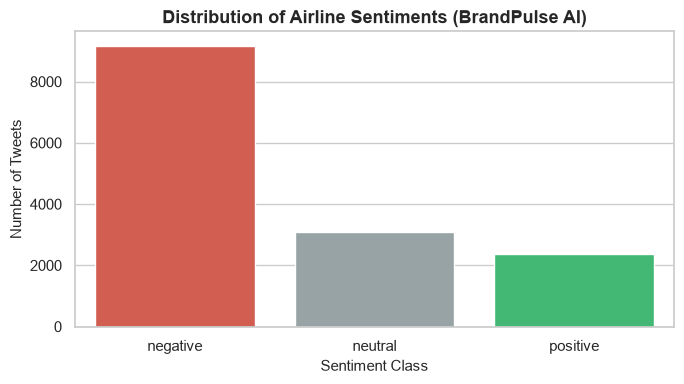

In [3]:
plt.figure(figsize=(7, 4))
sns.countplot(
    data=df, 
    x='airline_sentiment', 
    order=['negative', 'neutral', 'positive'], 
    palette=['#e74c3c', '#95a5a6', '#2ecc71']
)
plt.title("Distribution of Airline Sentiments (BrandPulse AI)", fontsize=13, fontweight='bold')
plt.xlabel("Sentiment Class", fontsize=11)
plt.ylabel("Number of Tweets", fontsize=11)
plt.tight_layout()
plt.show()

In [4]:
# Inspect 5 random tweets
sample_tweets = df[['airline_sentiment', 'text']].sample(5, random_state=42)

for idx, row in sample_tweets.iterrows():
    print(f"[{row['airline_sentiment'].upper()}]:")
    print(f"{row['text']}")
    print("-" * 60)

[POSITIVE]:
@SouthwestAir you're my early frontrunner for best airline! #oscars2016
------------------------------------------------------------
[NEGATIVE]:
@USAirways how is it that my flt to EWR was Cancelled Flightled yet flts to NYC from USAirways are still flying?
------------------------------------------------------------
[NEGATIVE]:
@JetBlue what is going on with your BDL to DCA flights yesterday and today?! Why is every single one getting delayed?
------------------------------------------------------------
[NEUTRAL]:
@JetBlue do they have to depart from Washington, D.C.??
------------------------------------------------------------
[NEGATIVE]:
@JetBlue I can probably find some of them. Are the ticket #s on there?
------------------------------------------------------------


In [5]:
import re

def clean_tweet_text(text):
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove URLs (http:// or https:// or www.)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    
    # 3. Remove User Mentions (@username)
    text = re.sub(r'@[A-Za-z0-9_]+', '', text)
    
    # 4. Remove hashtag symbols but keep the tag word (e.g., #delayed -> delayed)
    text = re.sub(r'#([A-Za-z0-9_]+)', r'\1', text)
    
    # 5. Remove special characters, numbers, and punctuation (keep only letters)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # 6. Remove excess whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# Test on a realistic noisy tweet
dummy_tweet = "@VirginAmerica I waited 4 hours! http://t.co/xyz #delayed & cold burger... REALLY???"
print("Original Tweet:\n", dummy_tweet)
print("\nCleaned Tweet:\n", clean_tweet_text(dummy_tweet))

Original Tweet:
 @VirginAmerica I waited 4 hours! http://t.co/xyz #delayed & cold burger... REALLY???

Cleaned Tweet:
 i waited hours delayed cold burger really


In [6]:

# Apply cleaning to the entire dataset
df['clean_text'] = df['text'].apply(clean_tweet_text)

# Inspect before vs after on 3 rows
df[['text', 'clean_text', 'airline_sentiment']].head(3)

,text,clean_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,what said,neutral
1,@VirginAmerica plus you've added commercials t...,plus youve added commercials to the experience...,positive
2,@VirginAmerica I didn't today... Must mean I n...,i didnt today must mean i need to take another...,neutral


In [7]:
# Check how many became empty or pure whitespace
empty_count = (df['clean_text'].str.strip() == '').sum()
print(f"Number of empty tweets after cleaning: {empty_count}")

# Filter out empty rows if any exist
df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
print(f"Remaining valid tweets: {len(df)}")

Number of empty tweets after cleaning: 0
Remaining valid tweets: 14640


In [8]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download necessary NLTK data assets
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Initialize lemmatizer
lemmatizer = WordNetLemmatizer()

# Load default English stop words
stop_words = set(stopwords.words('english'))

# Keep negation words so sentiment context is not reversed
negation_words = {'not', 'no', 'nor', 'neither', 'never', 'cannot', "don't", "aren't", "wasn't"}
stop_words = stop_words - negation_words

def lemmatize_and_remove_stopwords(text):
    words = text.split()
    # Lemmatize and filter out stop words
    filtered_words = [
        lemmatizer.lemmatize(w) 
        for w in words 
        if w not in stop_words and len(w) > 1
    ]
    return " ".join(filtered_words)

# Quick demonstration
sample_text = "the flights were delayed and not arriving on time"
print("Original clean text:", sample_text)
print("After lemmatization & stop words:", lemmatize_and_remove_stopwords(sample_text))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anj\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\anj\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\anj\AppData\Roaming\nltk_data...


Original clean text: the flights were delayed and not arriving on time
After lemmatization & stop words: flight delayed not arriving time


In [9]:
# Apply lemmatization across the cleaned text column
df['processed_text'] = df['clean_text'].apply(lemmatize_and_remove_stopwords)

# Drop any rows that may have become empty after stopword removal
df = df[df['processed_text'].str.strip() != ''].reset_index(drop=True)

# Inspect total tweets and first 3 rows
print(f"Total processed tweets ready for modeling: {len(df)}")
df[['text', 'processed_text', 'airline_sentiment']].head(3)


Total processed tweets ready for modeling: 14621


,text,processed_text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,said,neutral
1,@VirginAmerica plus you've added commercials t...,plus youve added commercial experience tacky,positive
2,@VirginAmerica I didn't today... Must mean I n...,didnt today must mean need take another trip,neutral


In [10]:
# Save clean dataset to data/processed/
df.to_csv("../data/processed/cleaned_tweets.csv", index=False)
print("Saved processed data to data/processed/cleaned_tweets.csv")


Saved processed data to data/processed/cleaned_tweets.csv


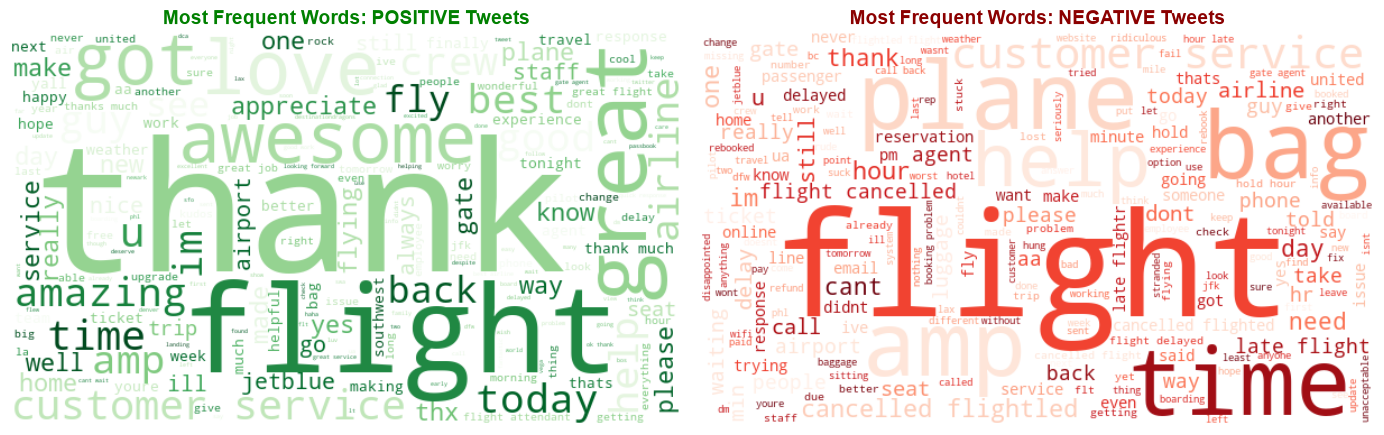

In [11]:
from wordcloud import WordCloud

# Separate positive and negative processed texts
pos_text = " ".join(df[df['airline_sentiment'] == 'positive']['processed_text'])
neg_text = " ".join(df[df['airline_sentiment'] == 'negative']['processed_text'])

# Create WordCloud objects
pos_wc = WordCloud(width=600, height=350, background_color='white', colormap='Greens').generate(pos_text)
neg_wc = WordCloud(width=600, height=350, background_color='white', colormap='Reds').generate(neg_text)

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(pos_wc, interpolation='bilinear')
axes[0].set_title('Most Frequent Words: POSITIVE Tweets', fontsize=14, fontweight='bold', color='green')
axes[0].axis('off')

axes[1].imshow(neg_wc, interpolation='bilinear')
axes[1].set_title('Most Frequent Words: NEGATIVE Tweets', fontsize=14, fontweight='bold', color='darkred')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

# Define feature text and target label
X = df['processed_text']
y = df['airline_sentiment']

# 80% train, 20% test with stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")

Training samples: 11696
Testing samples:  2925


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Configure vectorizer: unigrams + bigrams, top 5000 informative features
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

# Fit ONLY on training data to prevent data leakage, then transform
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF Matrix Shape (Train): {X_train_tfidf.shape}")
print(f"TF-IDF Matrix Shape (Test):  {X_test_tfidf.shape}")

TF-IDF Matrix Shape (Train): (11696, 5000)
TF-IDF Matrix Shape (Test):  (2925, 5000)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# 1. Use the 'lbfgs' solver explicitly (bypasses _liblinear)
log_reg = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)
nb_model = MultinomialNB()

# 2. Train Naive Bayes first
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)
print(f"Multinomial Naive Bayes Accuracy: {accuracy_score(y_test, y_pred_nb):.4f}")

# 3. Train Logistic Regression with lbfgs solver
log_reg.fit(X_train_tfidf, y_train)
y_pred_lr = log_reg.predict(X_test_tfidf)
print(f"Logistic Regression (L-BFGS) Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")


Multinomial Naive Bayes Accuracy: 0.7419
Logistic Regression (L-BFGS) Accuracy: 0.7860


In [17]:
from sklearn.metrics import classification_report

print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_lr, digits=4))


--- Logistic Regression Classification Report ---
              precision    recall  f1-score   support

    negative     0.8111    0.9384    0.8701      1835
     neutral     0.6513    0.4806    0.5531       618
    positive     0.8092    0.5932    0.6846       472

    accuracy                         0.7860      2925
   macro avg     0.7572    0.6707    0.7026      2925
weighted avg     0.7771    0.7860    0.7732      2925



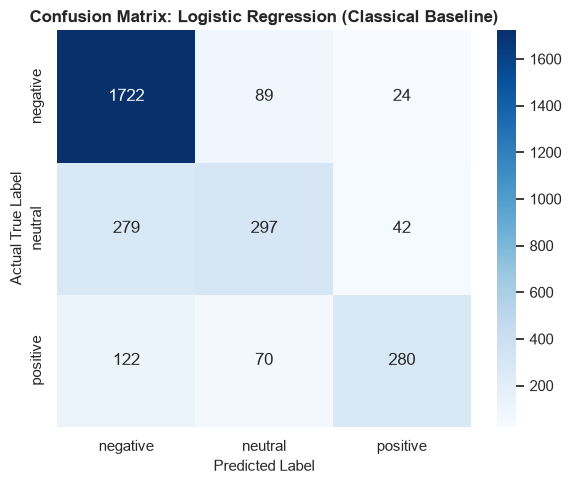

In [18]:
from sklearn.metrics import confusion_matrix

labels = ['negative', 'neutral', 'positive']
cm = confusion_matrix(y_test, y_pred_lr, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Logistic Regression (Classical Baseline)", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Actual True Label", fontsize=11)
plt.tight_layout()
plt.show()


In [19]:
import joblib

# Save both into the models directory
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")
joblib.dump(log_reg, "../models/logistic_model.pkl")

print("Successfully saved tfidf_vectorizer.pkl and logistic_model.pkl to ../models/")


Successfully saved tfidf_vectorizer.pkl and logistic_model.pkl to ../models/
